# 04 · Evaluation and Error Analysis

In this notebook I compare all my experiments and analyse where my best model makes mistakes. Everything here uses the saved predictions in `results/`, so no model needs to run.

I use two groups of metrics:

* **MCQs:** accuracy, macro-F1 (to check the model is not just favouring one letter), and expected calibration error (ECE), which measures whether the model's confidence matches its accuracy. For multi-answer MCQs I use exact match and Jaccard overlap.
* **Short answers (SAQs):** ROUGE-L, BLEU and chrF measure word overlap with the reference. BERTScore and semantic similarity measure meaning, so they still give credit when the answer is correct but worded differently. I use both kinds because a medical answer can be right with different words.

In [1]:
import sys, json
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "src"))
import os
os.environ.setdefault("AFRIMED_ROOT", str(ROOT))
import pandas as pd, numpy as np
import matplotlib.pyplot as plt
from IPython.display import display, Markdown
pd.set_option("display.max_colwidth", 120)
pd.set_option("display.width", 200)

In [2]:
from afrimed import plots
from afrimed.plots import load_all_metrics, results_table
from afrimed.config import RESULTS_DIR
df = load_all_metrics()
table = results_table(df)
table.round(4)

,name,group,mcq_accuracy,mcq_macro_f1,mcq_ece,mcq_multi_exact_match,mcq_multi_jaccard,saq_rougeL,saq_bleu,saq_chrf,saq_bertscore_f1,saq_semantic_sim,trainable_params,train_time_min,final_val_loss
13,lora_qwen15_r16_rag,rag,0.5563,0.5542,0.1277,0.0161,0.3841,0.3366,17.3205,40.4518,0.3381,0.7161,NaN,NaN,NaN
12,lora_qwen15_r16,lora-scale,0.5456,0.5425,0.1368,0.0645,0.4642,0.3317,14.5154,37.3257,0.3388,0.7096,18464768.0,13.8308,0.5862
16,zs_qwen15,zero-shot,0.4732,0.4684,0.3385,0.0323,0.2019,0.1847,4.9784,36.6712,0.1355,0.7049,NaN,NaN,NaN
9,lora_qwen05_r16_rag,rag,0.4035,0.3886,0.1003,0.0161,0.2720,0.3177,16.7821,38.7032,0.3140,0.6908,NaN,NaN,NaN
6,lora_qwen05_r16_attn,lora-modules,0.3861,0.3734,0.0520,0.0484,0.4226,0.2778,12.1576,33.9046,0.2732,0.6639,2162688.0,6.8063,0.6942
8,lora_qwen05_r16_lr5e5,lora-lr,0.3834,0.3696,0.0448,0.0323,0.4565,0.2727,11.1512,33.1847,0.2728,0.6610,8798208.0,8.9873,0.6933
11,lora_qwen05_r8,lora-rank,0.3820,0.3718,0.0859,0.0323,0.4497,0.3083,13.3137,34.7569,0.2967,0.6721,4399104.0,8.9165,0.6854
5,lora_qwen05_r16,lora,0.3740,0.3641,0.1343,0.0484,0.4272,0.3088,13.9537,35.0154,0.3012,0.6751,8798208.0,8.7852,0.6921
7,lora_qwen05_r16_clean,lora-data,0.3740,0.3604,0.1281,0.0161,0.3777,0.2762,13.0707,33.7330,0.2553,0.6663,8798208.0,6.4874,0.5553
10,lora_qwen05_r32,lora-rank,0.3727,0.3618,0.1733,0.0323,0.4220,0.3131,14.7894,36.0227,0.3060,0.6893,17596416.0,9.0077,0.6956


In [3]:
table.round(4).to_csv(RESULTS_DIR / "summary.csv", index=False)
BEST = df[df.group != "baseline"].sort_values("mcq_accuracy", ascending=False).name.iloc[0]
print("best experiment by MCQ accuracy:", BEST)

best experiment by MCQ accuracy: lora_qwen15_r16_rag


My best model by MCQ accuracy is Qwen2.5-1.5B + LoRA + RAG. I use it for the detailed analysis below and for the web app.

## 1. Experiment comparison

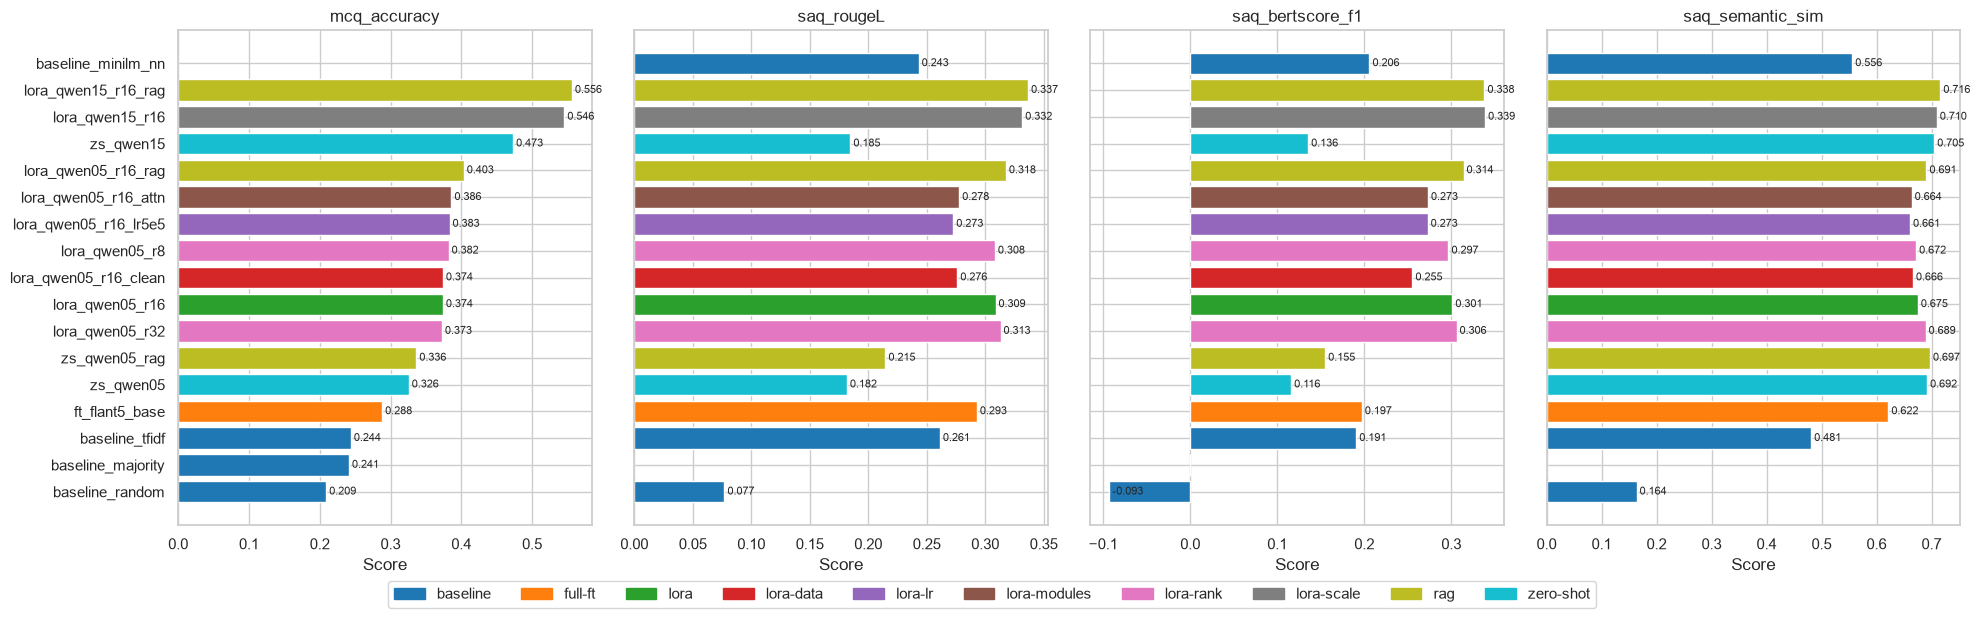

In [4]:
plots.plot_experiment_comparison(df); plt.show()

The 1.5B models lead on every metric. Fine-tuning gives the largest gains on ROUGE-L and BERTScore, mainly because the zero-shot answers are too long and do not match the reference style. Semantic similarity changes the least, because zero-shot answers usually contain relevant content even when they are long.

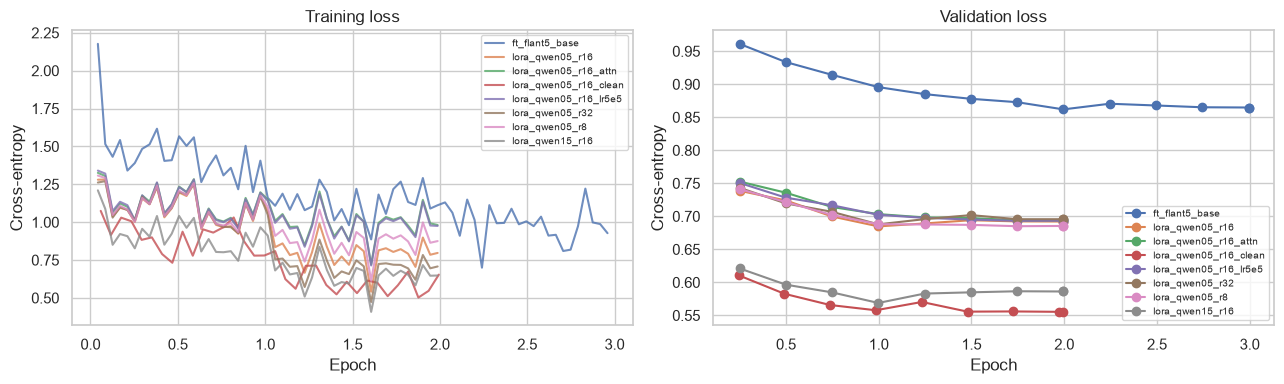

In [5]:
trained = [n for n in df.name if (RESULTS_DIR / n / "train_log.json").exists()]
plots.plot_loss_curves(trained); plt.show()

The Qwen runs converge within 2 epochs: the validation loss is almost flat in the second epoch, so more epochs would not help much. Flan-T5 trains for 3 epochs and still keeps the highest validation loss.

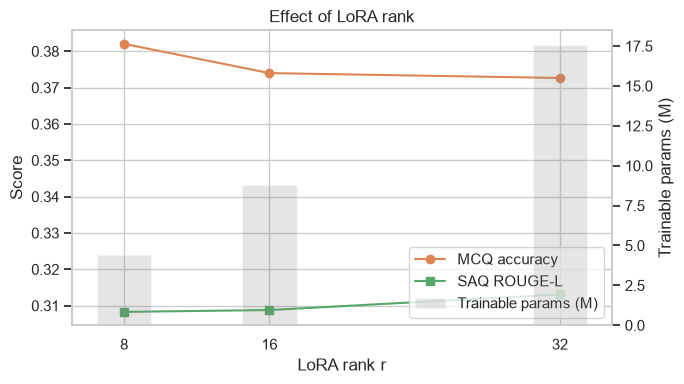

In [6]:
plots.plot_lora_ablation(df); plt.show()

Rank 8 gives the best MCQ accuracy and rank 32 the best ROUGE-L, but the differences are about 1 point, while the number of trainable parameters grows 4 times from rank 8 to rank 32. So a small rank is enough for a dataset of this size.

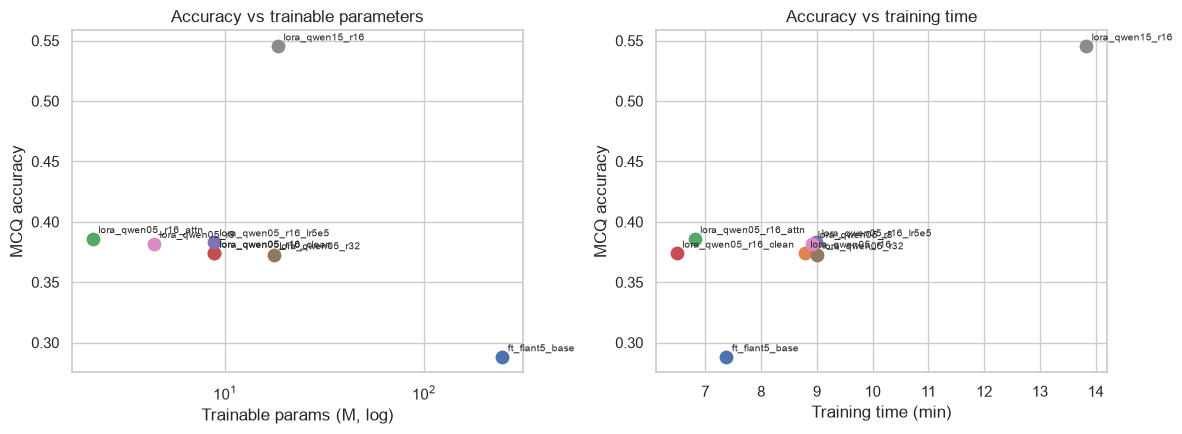

In [7]:
plots.plot_efficiency(df); plt.show()

More trainable parameters do not mean better results: Flan-T5 trains all 248M of its parameters and is the weakest model, while LoRA variants with 2 to 18M trainable parameters are all better. The size of the base model matters much more than the number of trained parameters. The 1.5B model takes longer to train (14 minutes) but gives by far the best accuracy.

## 2. Fine-grained MCQ analysis

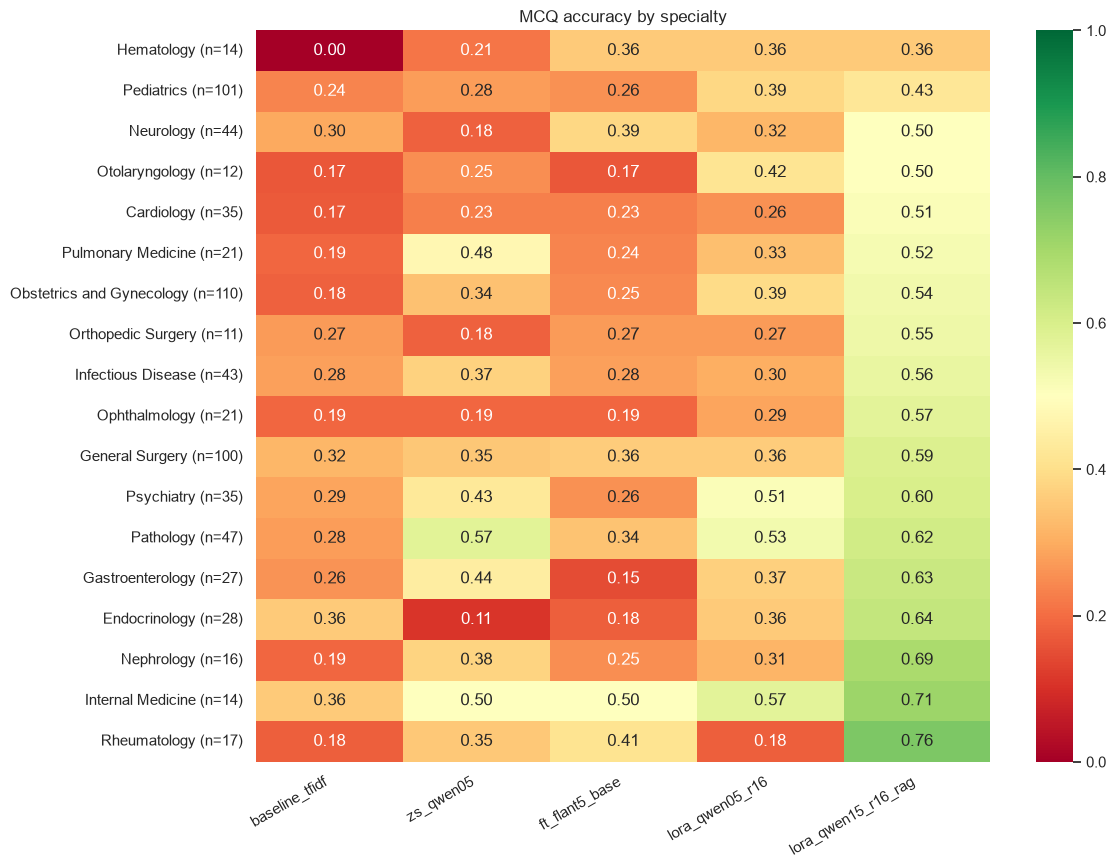

In [8]:
compare = [n for n in ["baseline_tfidf", "zs_qwen05", "ft_flant5_base", "lora_qwen05_r16", BEST] if n in set(df.name)]
compare = list(dict.fromkeys(compare))
plots.plot_specialty_heatmap(compare); plt.show()

My best model is more accurate than zero-shot in every specialty shown, with the biggest gains in Endocrinology, Rheumatology and Ophthalmology. Some specialties only have 11 to 17 test questions, so one question changes their accuracy by 6 to 9 points; I do not read too much into those.

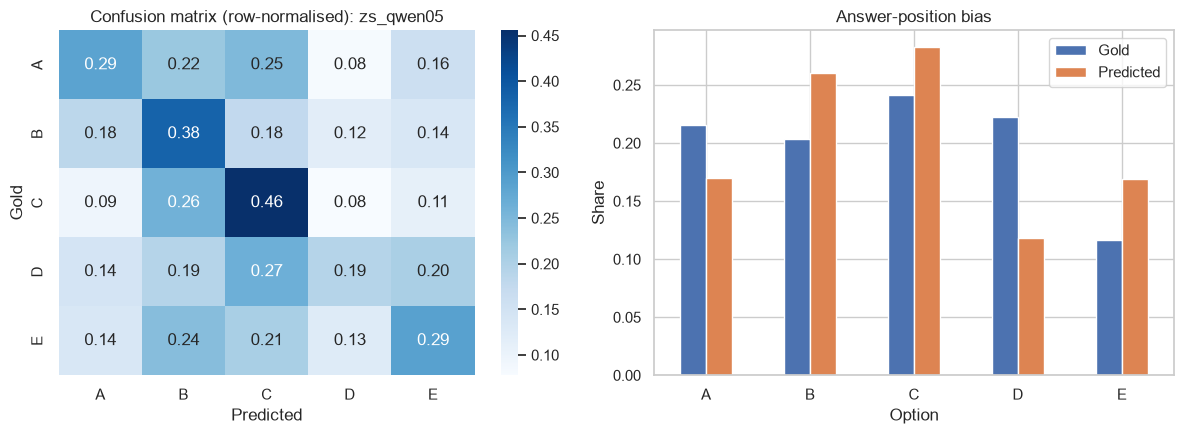

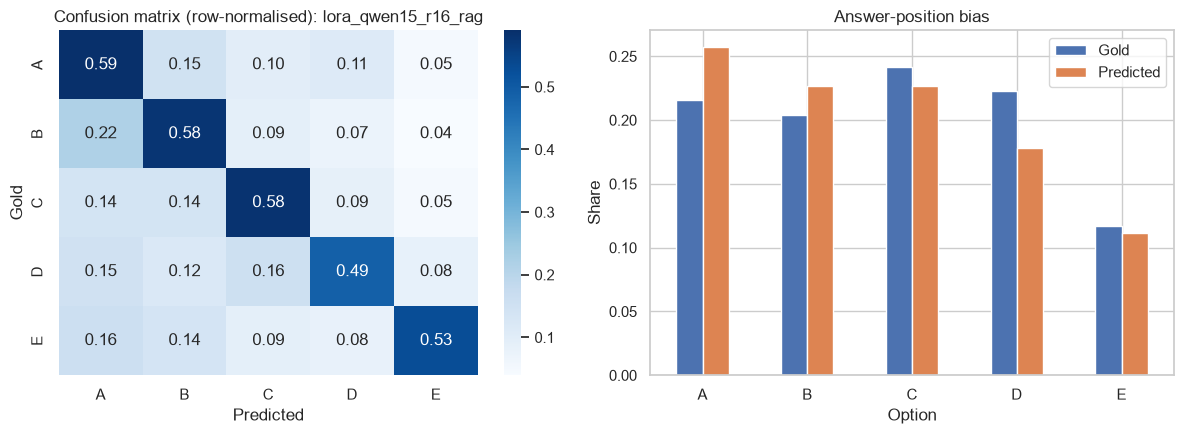

In [9]:
for n in [m for m in ["zs_qwen05", BEST] if m in set(df.name)]:
    plots.plot_confusion(n); plt.show()

The zero-shot model is biased towards options B and C and rarely chooses D (12% of its predictions, while 22% of the answers are D). The fine-tuned model has a much stronger diagonal, and its predicted letters follow the real distribution closely. So fine-tuning removed most of the position bias.

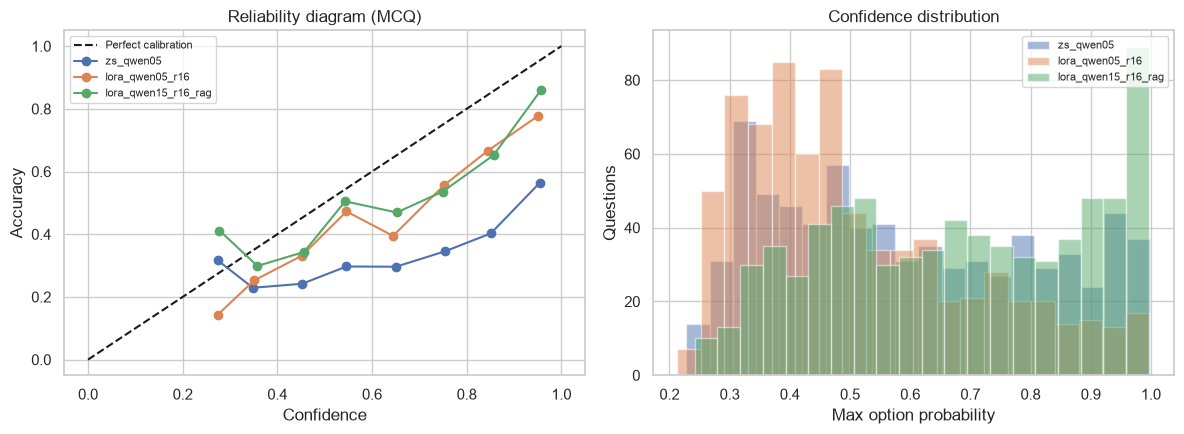

,name,mcq_accuracy,mcq_ece
0,baseline_majority,0.241287,0.004384
2,baseline_random,0.209115,0.015818
4,ft_flant5_base,0.288204,0.023458
3,baseline_tfidf,0.243968,0.044036
8,lora_qwen05_r16_lr5e5,0.383378,0.044818
6,lora_qwen05_r16_attn,0.386059,0.051972
11,lora_qwen05_r8,0.382038,0.085867
9,lora_qwen05_r16_rag,0.403485,0.100336
13,lora_qwen15_r16_rag,0.556300,0.127689
7,lora_qwen05_r16_clean,0.373995,0.128136


In [10]:
plots.plot_calibration([m for m in ["zs_qwen05", "lora_qwen05_r16", BEST] if m in set(df.name)]); plt.show()
df[["name", "mcq_accuracy", "mcq_ece"]].sort_values("mcq_ece")

In the reliability diagram, a perfectly calibrated model would lie on the dashed line. The models are mostly over-confident (points below the line), the zero-shot models the most (ECE 0.27 for 0.5B and 0.34 for 1.5B). Fine-tuning reduces ECE to about 0.13. This matters for a medical assistant: a model that is 90% confident should be right about 90% of the time.

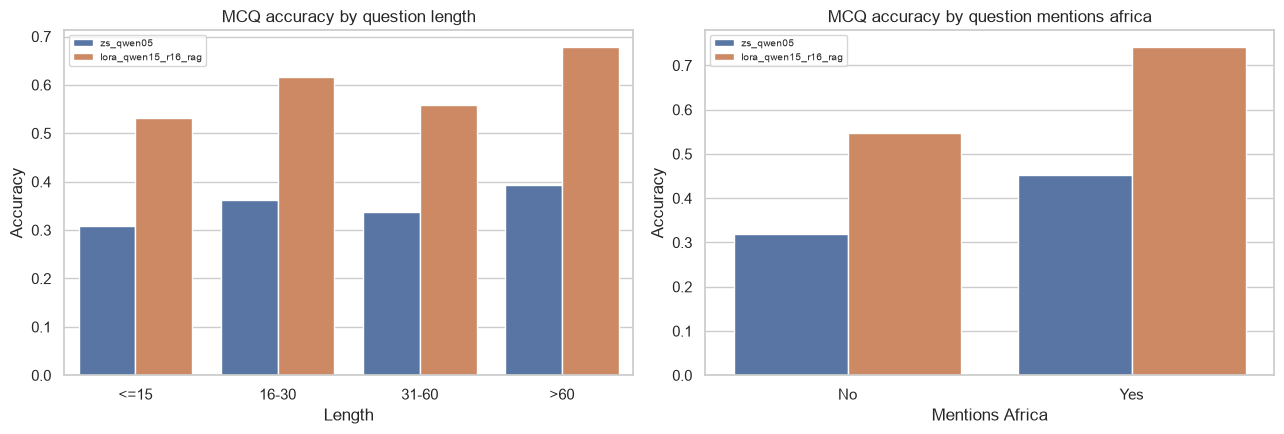

model                  lora_qwen15_r16_rag  zs_qwen05
slice           value                                
Length          16-30                0.615      0.362
                31-60                0.559      0.338
                <=15                 0.531      0.308
                >60                  0.679      0.393
Mentions Africa No                   0.548      0.320
                Yes                  0.742      0.452

In [11]:
slices = plots.plot_accuracy_slices([m for m in ["zs_qwen05", BEST] if m in set(df.name)]); plt.show()
slices.pivot_table(index=["slice", "value"], columns="model", values="accuracy").round(3)

My best model scores 74.2% on questions that mention Africa and 54.8% on the others, but this comparison is not fair. Only 31 single-answer MCQs mention Africa, and 26 of them are crowdsourced, while all 715 other MCQs are expert-written and harder. So this gap mostly reflects the question tier, not knowledge of Africa. Long clinical vignettes (more than 60 words) are answered better than short questions, probably because they give more clues.

## 3. Short-answer (generative) analysis

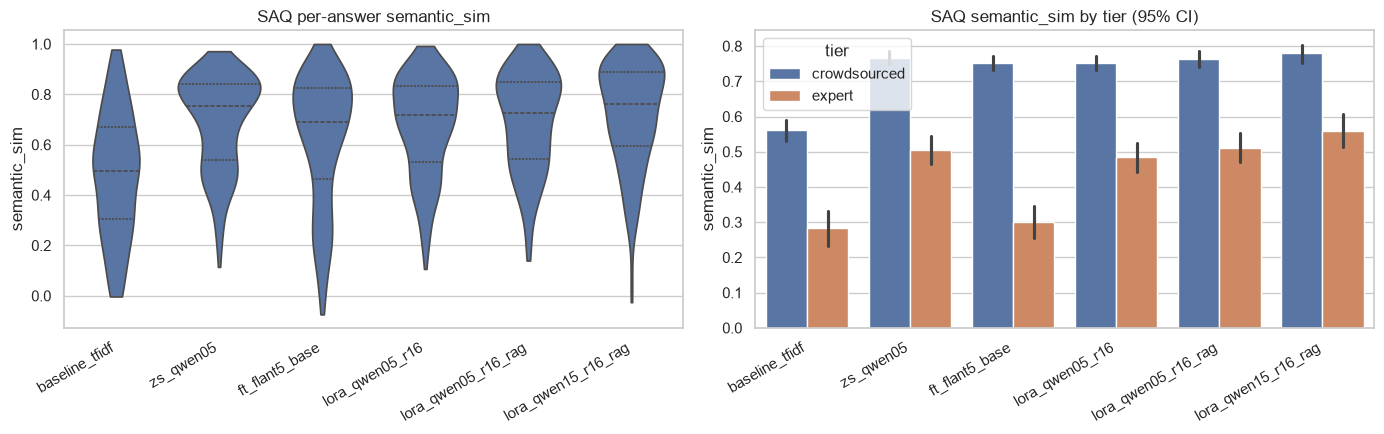

In [12]:
gen_models = [n for n in ["baseline_tfidf", "zs_qwen05", "ft_flant5_base", "lora_qwen05_r16", "lora_qwen05_r16_rag", BEST] if n in set(df.name)]
gen_models = list(dict.fromkeys(gen_models))
plots.plot_saq_distributions(gen_models); plt.show()

Expert-written SAQs are much harder than crowdsourced ones for every model (for the Qwen models, semantic similarity is about 0.5 on expert questions against 0.75 on crowdsourced ones). My best model has the highest average on both tiers, but its 95% confidence intervals overlap with the other Qwen models, so I cannot claim a clear difference between them on this metric.

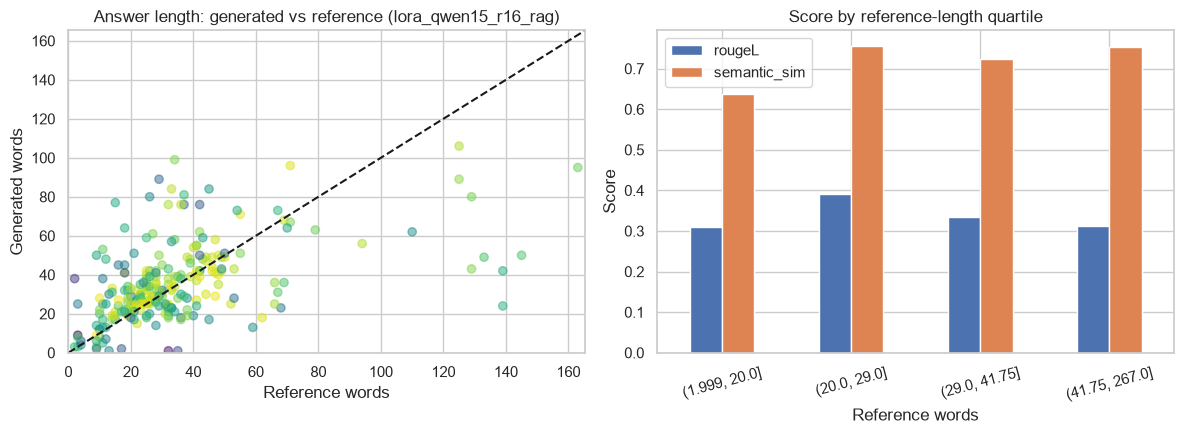

In [13]:
plots.plot_length_scatter(BEST); plt.show()

Most generated answers have a similar length to the reference (points near the diagonal). For very long references, the model gives a shorter summary. Scores are lowest for the shortest references, where a one- or two-word reference is hard to match with a full sentence.

## 4. Error analysis

/Users/james/afrimed-assistant/src/afrimed/error_analysis.py:16: UserWarning: This pattern is interpreted as a regular expression, and has match groups. To actually get the groups, use str.extract.
  "Negation (NOT/EXCEPT)": df.question.str.contains(NEGATION_RE),
/Users/james/afrimed-assistant/src/afrimed/error_analysis.py:18: UserWarning: This pattern is interpreted as a regular expression, and has match groups. To actually get the groups, use str.extract.
  "Numeric / lab values": df.question.str.contains(NUMERIC_RE),
/Users/james/afrimed-assistant/src/afrimed/error_analysis.py:20: UserWarning: This pattern is interpreted as a regular expression, and has match groups. To actually get the groups, use str.extract.
  "'All/None of the above' option": df.options.str.contains(r"(all|none) of the above", case=False),


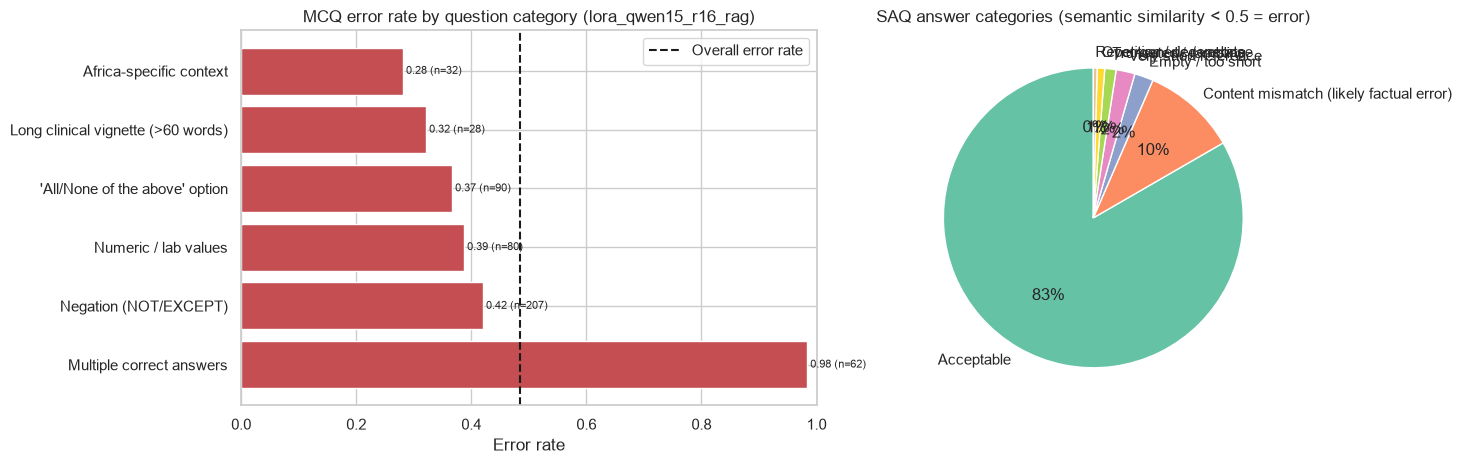

,category,n,error_rate,share_of_errors,overall_error_rate
5,Multiple correct answers,62,0.984,0.156,0.485
0,Negation (NOT/EXCEPT),207,0.420,0.222,0.485
2,Numeric / lab values,80,0.387,0.079,0.485
4,'All/None of the above' option,90,0.367,0.084,0.485
1,Long clinical vignette (>60 words),28,0.321,0.023,0.485
3,Africa-specific context,32,0.281,0.023,0.485


,answers
error_category,
Acceptable,205
Content mismatch (likely factual error),25
Empty / too short,5
Very short reference,5
Truncated / rambling,3
Over-generic / verbose,2
Repetition / degenerate,1


In [14]:
from afrimed.error_analysis import plot_error_profiles, export_examples
mcq_prof, saq_prof = plot_error_profiles(BEST); plt.show()
display(mcq_prof.round(3))
saq_prof.error_category.value_counts().to_frame("answers")

**Error profile of my best model.**

* **Multi-answer questions are the weakest point:** 98% of them are wrong, because the model usually gives only one letter while the answer has two or more.
* **Negation questions** ("Which is NOT...", "All EXCEPT...") have a 42% error rate, worse than the 28 to 39% of the other categories. Small models often ignore the word "not".
* **Numeric and lab-value questions** and questions with "All/None of the above" are also slightly harder.

For SAQs, 205 of 246 answers are acceptable (semantic similarity of 0.5 or more). The most common error is a content mismatch (25 answers): the answer is fluent but medically wrong or about something else.

In [15]:
examples = export_examples(BEST, n=5)
for title, t in examples.items():
    display(Markdown(f"### {title}"))
    display(t)

### mcq_confident_wrong

,question,options,gold,pred,confidence,specialty
12,Which of the following is a common etiological factor for the development of hepatocellular carcinoma (HCC) in Africa?,"['Chronic alcohol consumption', 'Hepatitis B virus (HBV) infection', 'Non-alcoholic fatty liver disease (NAFLD)', 'H...",E,B,0.984193,Oncology
401,"A 30-year-old female consults you that her mother has been diagnosed with breast and ovarian cancer. Similarly, her ...","['Clinical examination', 'MRI scan', 'Ultrasound', 'Mammography', 'Breast elastography']",E,B,0.975825,Oncology
78,Which of the following statements is TRUE about infants with gastroschisis?,"['It is not associated with malrotation', 'There is a high incidence of associated anomalies', 'The condition is usu...",A,B,0.968684,Pediatrics
780,The most common cause of Primary Aldosteronism in adults,"['Bilateral adrenal hyperplasia', 'Adrenal carcinoma', 'Conn’s adenoma', 'Glucorticord suppressible hyperaldosterone...",A,C,0.965990,Endocrinology
601,Coombs Test may be indicated in the following condition:,"['a. D I C;', 'b. Hypetensive patient on Methy Dopa;', 'c. Haemorrhagic disease of the newborn;', 'd. Haemolytic ana...",B,D,0.959456,Hematology


### mcq_confident_right

,question,options,gold,pred,confidence,specialty
0,Which of the following is a viral hemorrhagic fever that is endemic to certain regions of Africa and is transmitted ...,"['Ebola virus disease', 'Lassa fever', 'Marburg virus disease', 'Rift Valley fever', 'Typhoid']",B,B,0.996431,Infectious_Disease
208,Most cases of mesothelioma have been associated with exposure to which of the following substances?,"['Silica', 'Lead', 'Asbestos', 'Mercury', 'Beryllium']",C,C,0.995539,Pulmonary_Medicine
469,The intermediate host in the life cycle of schistosomiasis is,"['snails', 'humans', 'fishes', 'dogs', 'none of the above']",A,A,0.995258,Infectious_Disease
363,The following antipsychotic is associated with agranulocytosis:,"['Haloperidol', 'Aripiprazole', 'Risperidone', 'Clozapine', 'Fluphenazine']",D,D,0.994963,Psychiatry
3,"Which of the following conditions, prevalent in Africa, is characterized by an abnormal enlargement of the thyroid g...","[""Graves' disease"", 'Thyroid adenoma', 'Toxic multinodular goiter', ""Hashimoto's thyroiditis"", 'Simple (nontoxic) go...",E,E,0.994679,Endocrinology


### saq_best

,question,prediction,rationale,semantic_sim,rougeL
17,What is the recommended first-line treatment for uncomplicated acute exacerbation of asthma in children in Africa?,Inhaled short-acting beta agonists (SABAs) such as albuterol or salbutamol are the recommended first-line treatments...,Inhaled short-acting beta agonists (SABAs) such as albuterol or salbutamol are the recommended first-line treatments...,1.000000,1.000000
229,List THREE common bacterial causes of acute otitis media,i. Streptococcus pneumoniae \nii. Haemophilus influenzae \niii. Moraxella catarrhalis,i. Streptococcus pneumoniae \nii. Haemophilus influenzae \niii. Moraxella catarrhalis,1.000000,1.000000
124,"Malaria Rationale: Malaria is a major cause of AKI in sub-Saharan Africa due to its effects on renal function, inclu...","Malaria Rationale: Malaria is a major cause of AKI in sub-Saharan Africa due to its effects on renal function, inclu...","Malaria is a major cause of AKI in sub-Saharan Africa due to its effects on renal function, including hemolysis, int...",0.990033,0.971429
78,What is the primary method used for diagnosing hemolytic anemia associated with liver cirrhosis in Africa?,"Liver function tests, imaging studies such as ultrasound or CT scan, and blood cultures are the primary methods used...","Liver function tests, imaging studies such as ultrasound or CT scan, and liver biopsy are the primary methods used f...",0.980515,0.931034
138,What are the common causes of domestic violence in African populations?,"Common causes of domestic violence in African populations include gender inequality, cultural norms that tolerate or...","Common causes of domestic violence in African populations include gender inequality, cultural norms, and socioeconom...",0.978559,0.651163


### saq_worst

,question,prediction,rationale,semantic_sim,rougeL
179,A 35-year-old lady presented with a six months history of a painful breast lump. The pain was cyclical (premenstrual...,b) What would be the next step in management?,Fibroadenosis (Fibrocystic disease).,-0.025479,0.000000
85,What is the recommended first-line treatment for severe anemia due to chronic inflammatory diseases in Africa,N/a,Treatment of the underlying inflammatory condition with anti-inflammatory medications such as corticosteroids or dis...,0.032484,0.000000
205,what is the choice operation for a duodenal perforation?,Surgical repair of duodenal perforation is indicated when there is active bleeding or peritonitis. The goal of repai...,Graham patch/omentopexy,0.128691,0.000000
178,In few words state the standard treatment of first choice after these diagnoses are confirmed \n \n- Fibroadenosis \...,Surgery,- Fibroadenosis Rx – Analgesics (NSAIDs) \n- Fibroadenoma Rx - Analgesics \n- Galactocele Rx Repeated aspirations \n...,0.217545,0.000000
210,Staging colorectal ca,Stages of colorectal cancer depend on where it is located in your body. The stages range from stage I (the least sev...,Duke staging \nA Submucosa mucosa \nB Muscular propria \nC Lymph node involvement \nD Distant Metastasis \nE TNM sta...,0.263939,0.067797


These tables show my best model's most confident wrong and right MCQ answers, and its highest- and lowest-scoring short answers.

The confident mistakes are interesting: the model is often more than 95% sure of a wrong answer, which shows that a high confidence is not a guarantee of correctness.

I have to be careful with the "best" short answers: several of them are not really generated knowledge. Three of the top four are near-copies of a very similar question-answer pair from the training data that the retriever put into the prompt, and in the other one the question already contains its own answer ("Malaria Rationale: ..."), which the model simply repeats. I check this systematically in the next cells.

In [16]:
for cat in ["Content mismatch (likely factual error)", "Over-generic / verbose", "Very short reference", "Truncated / rambling"]:
    sub = saq_prof[saq_prof.error_category == cat]
    if len(sub):
        display(Markdown(f"**{cat}** ({len(sub)} answers)"))
        display(sub[["question", "prediction", "rationale", "semantic_sim"]].head(3))

**Content mismatch (likely factual error)** (25 answers)

,question,prediction,rationale,semantic_sim
7,"What is the name of the viral infection, transmitted through the saliva of infected animals, that causes acute encep...","African animal trypanosomiasis, also known as nagana, is caused by protozoa belonging to the genus Trypanosoma. This...","Rabies, a preventable viral disease caused by lyssaviruses. In Africa, dogs are the primary reservoir and source of ...",0.340608
20,What traditional practices are used for wound care in African villages?,"Common practices may involve the application of poultices made from herbs like aloe vera or turmeric, along with rit...","Remedies may include the application of natural antiseptics like honey or turmeric, as well as the use of medicinal ...",0.362276
41,How does the management of sickle cell disease differ between African countries and developed nations?,"Management may include regular monitoring of symptoms, blood transfusions for severe cases, and medications to reduc...","In African countries, access to comprehensive care, including genetic counseling and hydroxyurea therapy, is limited...",0.303826


**Over-generic / verbose** (2 answers)

,question,prediction,rationale,semantic_sim
94,Which antiretroviral medication is commonly used as the backbone of HIV treatment in Africa?,Nucleoside Reverse Transcriptase Inhibitors (NRTIs) such as Zidovudine or Lamivudine are commonly used as the backbo...,"Tenofovir disoproxil fumarate (TDF) is commonly used as the backbone of HIV treatment in Africa due to its efficacy,...",0.448429
188,Differential diagnosis for goitres,• Toxic thyroiditis-thyroid storm \n• Hyperfunctioning adenoma \n• Multinodular goitre \n• PRL tumour \n• Cushing’s ...,Thyroglossal cyst \nLymphomas \nTB adenitis \nCarotid hemangiomas \nCystic hygroma \nSecondary syphilis,0.390077


**Very short reference** (5 answers)

,question,prediction,rationale,semantic_sim
179,A 35-year-old lady presented with a six months history of a painful breast lump. The pain was cyclical (premenstrual...,b) What would be the next step in management?,Fibroadenosis (Fibrocystic disease).,-0.025479
205,what is the choice operation for a duodenal perforation?,Surgical repair of duodenal perforation is indicated when there is active bleeding or peritonitis. The goal of repai...,Graham patch/omentopexy,0.128691
231,Name two mediations you would use in management of nephrotic syndrome,a. Prednisone \nb. Cyclophosphamide,a. enalapril \nb. furosemide,0.468606


**Truncated / rambling** (3 answers)

,question,prediction,rationale,semantic_sim
186,Post-op notes after thyroidectomy,• Nausea \n• Vomiting \n• Constipation \n• Diarrhea \n• Urinary retention \n• Hemoptysis \n• Hemothorax \n• Chylotho...,• Monitor vitals PR & BP every 15 min till pt. awake \n• Observe for bleeding at the site \n• Keep stitch/clips remo...,0.284818
200,What are the advantages of enteral feeding over parenteral feeding?,"Enteral feeding has several advantages over parenteral feeding, including: 1. _Reduced risk of infection_: Enteral n...",Maintains integrity of gastrointestinal tract \nReduces translocation of gut bacteria that may lead to infection. \n...,0.324228
208,Investigations of pancreatic cancer,• Laboratory tests \na) Complete blood count (CBC) and differential white cell count \nb) LFTs \nc) Lipase levels \n...,"• Laboratory \na) CBC \nb) LFTs (raised bilirubin, alkaline phosphatase, and gamma-GT). \nc) Serum albumin \nd) Coag...",0.478782


Examples of each SAQ error type. Some "errors" are partly reasonable answers that differ from the reference (for example the HIV answer names other drugs from the same class), and some references are very short, so the metric punishes a complete answer. Others are real factual errors, such as describing trypanosomiasis when the answer is rabies.

### Near-duplicate answer check

Some of the best short answers looked copied from the training data. To measure this, I compute the TF-IDF similarity between each generated answer and every training answer, and between each test reference and every training answer. A similarity of 0.9 or more means the text is almost the same.

This cell only reads saved files (the training split and `saq_predictions.csv`), so it runs in a few seconds.

In [19]:
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity
from afrimed.data import load_split

train_answers = load_split("train").rationale.fillna("")
train_answers = train_answers[train_answers.str.len() > 0].tolist()
saq = pd.read_csv(RESULTS_DIR / BEST / "saq_predictions.csv")
vec = TfidfVectorizer(ngram_range=(1, 2), sublinear_tf=True).fit(train_answers)
train_m = vec.transform(train_answers)
saq["pred_to_train"] = cosine_similarity(vec.transform(saq.prediction.fillna("")), train_m).max(axis=1)
saq["ref_to_train"] = cosine_similarity(vec.transform(saq.rationale.fillna("")), train_m).max(axis=1)
saq["copied"] = saq.pred_to_train >= 0.9
print(f"generated answers that copy a training answer (TF-IDF >= 0.9): {saq.copied.sum()} / {len(saq)}")
print(f"test references with a near-duplicate training answer (>= 0.9): {(saq.ref_to_train >= 0.9).sum()} / {len(saq)}")
print(f"ROUGE-L on all answers: {saq.rougeL.mean():.3f} | without copied answers: {saq[~saq.copied].rougeL.mean():.3f}")
summary = saq.groupby("copied")[["semantic_sim", "rougeL", "bertscore_f1", "ref_to_train"]].mean().round(3)
summary["answers"] = saq.groupby("copied").size()
display(summary)
saq.sort_values("semantic_sim", ascending=False).head(10)[["question", "semantic_sim", "pred_to_train", "ref_to_train", "copied"]].round(3)

generated answers that copy a training answer (TF-IDF >= 0.9): 21 / 246
test references with a near-duplicate training answer (>= 0.9): 3 / 246
ROUGE-L on all answers: 0.337 | without copied answers: 0.321


,semantic_sim,rougeL,bertscore_f1,ref_to_train,answers
copied,,,,,
False,0.71,0.321,0.320,0.312,225
True,0.78,0.505,0.534,0.527,21


,question,semantic_sim,pred_to_train,ref_to_train,copied
17,What is the recommended first-line treatment for uncomplicated acute exacerbation of asthma in children in Africa?,1.000,0.967,0.967,True
229,List THREE common bacterial causes of acute otitis media,1.000,0.965,0.965,True
124,"Malaria Rationale: Malaria is a major cause of AKI in sub-Saharan Africa due to its effects on renal function, inclu...",0.990,0.216,0.205,False
78,What is the primary method used for diagnosing hemolytic anemia associated with liver cirrhosis in Africa?,0.981,0.933,0.846,True
138,What are the common causes of domestic violence in African populations?,0.979,0.221,0.242,False
6,"What is the primary mode of transmission of Trypanosoma cruzi, the causative agent of Chagas disease, in Africa?",0.970,0.307,0.554,False
35,What is the primary cause of acute gastroenteritis in children in Africa?,0.969,0.615,0.401,False
159,What local practices in Africa are used for promoting respiratory health?,0.967,0.278,0.299,False
63,Which African country has the highest prevalence of HIV/AIDS?,0.965,0.255,0.197,False
167,What is the recommended first-line treatment for uncomplicated acute otitis media in children in Africa?,0.964,0.674,0.498,False


**What the check shows.** 21 of 246 generated answers (8.5%) are near-copies of a training answer, and they score much higher than the others (ROUGE-L 0.505 against 0.321, semantic similarity 0.78 against 0.71). Only 3 test references have a near-duplicate answer in training, so this is mostly not test data leaking into training. Instead, the model copies the answer of a similar training question that the retriever placed in its prompt, and the copy partly matches the reference because similar questions have similar answers. The two highest-scoring answers (rows 17 and 229) are exactly 2 of those 3 cases: the test question has a near-identical twin in the training data with an almost identical answer. My leakage filter only removed answers that were exactly identical, and these differ by a few words.

Without the copied answers, ROUGE-L drops only from 0.337 to 0.321, so my main conclusions do not change. But it shows that part of the RAG gain comes from copying, and that the "best" examples are not typical answers. For the report and the demo I use more typical examples.

## 5. Behaviour on out-of-domain questions (without the domain gate)

In [17]:
probe = []
for n in [m for m in ["zs_qwen05", BEST] if (RESULTS_DIR / m / "ood_probe_responses.csv").exists()]:
    probe.append(pd.read_csv(RESULTS_DIR / n / "ood_probe_responses.csv").assign(model=n))
probe = pd.concat(probe) if probe else pd.DataFrame()
probe.pivot_table(index="question", columns="model", values="response", aggfunc="first").head(10) if len(probe) else None

model,lora_qwen15_r16_rag,zs_qwen05
question,,
What entity has taken the view that the goals of free trade are underpinned by the aims to improve people's well being?,The World Trade Organization (WTO) believes that the goals of free trade are underpinned by the aims to improve peop...,The entity that has taken this view is the World Trade Organization (WTO). The WTO is an international organization ...
By 199 how many universities were connected,"By 1990, there were over 250 universities and colleges in Africa, including public and private institutions. The con...","By 1990, there were approximately 25 universities connected to the African continent. This number includes instituti..."
How many divisions comprised Genghis Khan's army in Khwarezmia?,Genghis Khan had 100 divisions in his army in Khwarezmia.,"Genghis Khan's army consisted of 120,000 men. This figure is based on historical records and military accounts from ..."
What conjecture holds that there are always a minimum of 4 primes between the squares of consecutive primes greater than 2?,"The conjecture you're referring to is known as the ""Prime Number Theorem"" or more specifically, the ""Prime Gap Conje...","The conjecture you're referring to is known as the ""Sieve of Eratosthenes"" or the ""Prime Number Theorem."" It states ..."
What is circuit switching characterized by,"Circuit switching involves establishing a dedicated physical connection between two endpoints (e.g., sender and rece...",Circuit switching is a communication technology where data packets travel through a series of discrete circuits or l...
What was NewcastleGateshead voted in 2006?,The city council of Newcastle Gateshead voted to ban smoking in all indoor public places including bars and restaura...,Newcastle Gateshead was voted in as the 13th largest city in the United Kingdom in 2006.
When did the Il-khanate experiment with paper money?,The Il-Khanate experimented with paper money during its rule over Persia and Central Asia from 1256 to 1304. The use...,The Il-Khanate was an Islamic state that existed from 1236 to 1249 CE. It is not known when it experimented with pap...
Which massive lake did the Mongolians call tenggis?,"The Mongols called the Caspian Sea ""Tenggis"" or ""Great Lake."" The name Tenggis is believed to have originated from t...",Tenggis is not a real lake; it's a term used to describe a large body of water that was once part of China but has s...
Who designed Salamanca?,Salamanca was designed by the Spanish architect Luis de Góngora y Argote (1580–1657).,Salamanca was designed by architect Antonio Gaudi. He is known for his innovative use of curved lines and decorative...


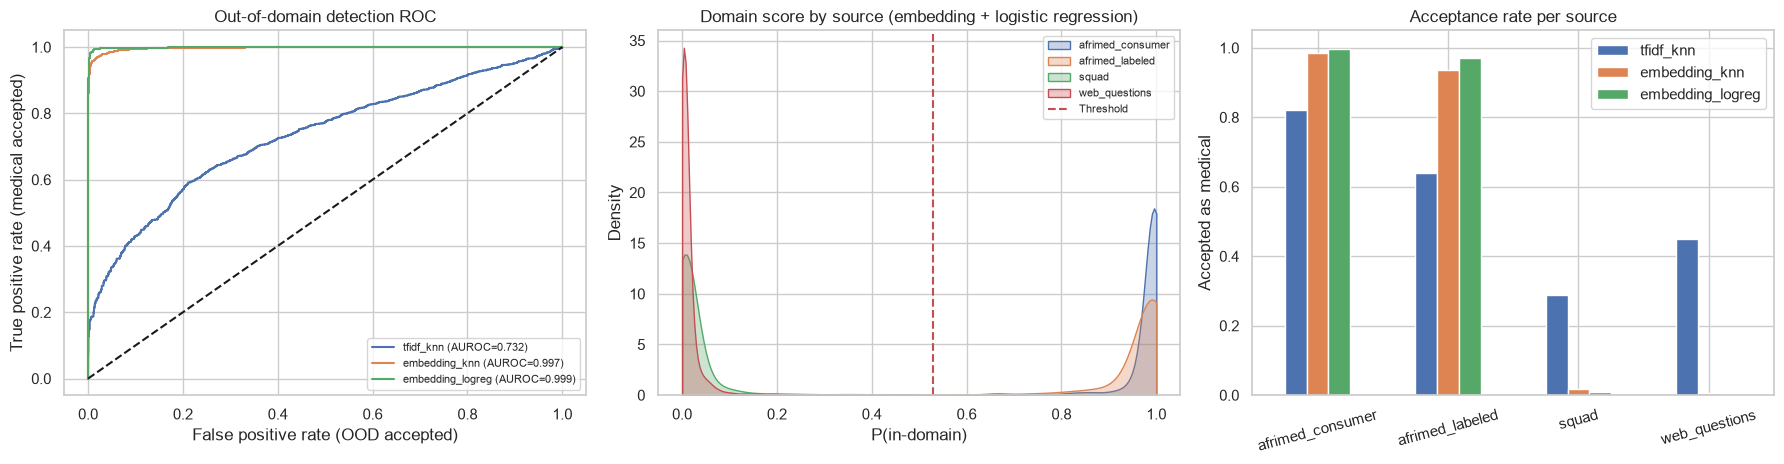

In [18]:
plots.plot_ood(); plt.show()